# H&M 고객 구매 패턴 분석과 RFM 고객 세분화

상품·고객·거래·이미지 데이터를 연결해 구매 패턴을 탐색하고 RFM으로 고객을 세분화한다. 전처리와 통계 로직은 `src/pipeline.py`의 `DataAnalyzer`에서 호출한다.

아래 표와 차트는 Kaggle에서 실행한 고객 100명 표본의 집계 결과다. 원본 데이터 행과 상품 사진 출력은 제외했다. 로컬에서 같은 분석을 실행하는 방법은 [README](../README.md)에 정리했다.

In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.pipeline import DataAnalyzer

DATA_DIR = Path(os.environ.get("HM_DATA_DIR", PROJECT_ROOT / "data"))
RANDOM_SEED = 42
analyzer = DataAnalyzer(DATA_DIR)

## 1. 데이터 로드 및 기본 탐색

- `transactions_train.csv`는 거래일, 고객 ID, 상품 ID, 정규화 가격, 판매 채널을 제공한다.
- `customers.csv`는 고객 나이와 멤버십 상태를 제공한다.
- `articles.csv`와 `images/`는 상품명, 종류, 색상, 상품 사진을 제공한다.

거래 이력이 있는 고객 ID를 정렬한 뒤 고정 시드로 100명을 뽑고, 선택된 고객의 관측 기간 거래를 모두 보존한다. 거래 CSV는 고객 ID 수집과 표본 추출을 위해 청크 단위로 두 번 읽는다. Kaggle 실행에서 고객 100명과 상품 2,152개에 해당하는 거래 2,606행이 추출되어, 구매일 수와 구매금액을 고객별로 집계할 수 있었다.

In [68]:
transactions, customers, articles = analyzer.load_data(
    sample_size=100, random_state=RANDOM_SEED
)
assert len(transactions) >= 1_000, "표본 거래가 1,000행 이상 필요합니다."

print("거래 표본:", transactions.shape)
print("고객 표본:", customers.shape)
print("상품 표본:", articles.shape)

for table in (transactions, customers, articles):
    display(table.head())
    table.info()

거래 표본: (2606, 5)
고객 표본: (100, 7)
상품 표본: (2152, 25)


## 2. 결측치 처리와 데이터 병합

멤버십 상태가 비어 있으면 `Unknown`으로 표시한다. 고객 나이는 동일 멤버십 그룹의 중앙값으로 대치하고, 남은 값에는 고객 전체 중앙값을 사용한다. 고객당 한 행인 상태에서 나이 중앙값을 구해 거래가 많은 고객의 나이가 중복 반영되는 것을 막는다.

거래를 기준으로 상품과 고객 정보를 연결한다. 거래 2,606행을 유지하므로 고객별 구매 이력을 그대로 집계할 수 있다.

In [69]:
display(articles.isna().sum())
display(customers.isna().sum())
display(transactions.isna().sum())

article_id                      0
product_code                    0
prod_name                       0
product_type_no                 0
product_type_name               0
product_group_name              0
graphical_appearance_no         0
graphical_appearance_name       0
colour_group_code               0
colour_group_name               0
perceived_colour_value_id       0
perceived_colour_value_name     0
perceived_colour_master_id      0
perceived_colour_master_name    0
department_no                   0
department_name                 0
index_code                      0
index_name                      0
index_group_no                  0
index_group_name                0
section_no                      0
section_name                    0
garment_group_no                0
garment_group_name              0
detail_desc                     7
dtype: int64

customer_id                0
FN                        66
Active                    66
club_member_status         1
fashion_news_frequency     2
age                        1
postal_code                0
dtype: int64

t_dat               0
customer_id         0
article_id          0
price               0
sales_channel_id    0
dtype: int64

In [102]:
customers["club_member_status"] = customers["club_member_status"].fillna("Unknown")
customers["age"] = analyzer.handle_missing_values(
    customers, "age", group_col="club_member_status", strategy="median"
)

customers.isna().sum()

customer_id                0
FN                        66
Active                    66
club_member_status         0
fashion_news_frequency     2
age                        0
postal_code                0
dtype: int64

In [ ]:
df = transactions.merge(
    articles,
    on="article_id",
    how="left",
    validate="many_to_one",
)


df = df.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
)


print(df.shape)
display(df.head())

df.isna().sum()

## 3. 텍스트 피처 생성

상품명의 문자 수를 계산해 `product_name_length` 컬럼을 추가한다.
공백과 숫자, 특수문자도 문자 수에 포함한다.

In [ ]:
df = analyzer.add_text_features(df)

display(
    df[["article_id", "prod_name", "product_name_length"]].head()
)

In [77]:
display(
    df.drop_duplicates("article_id")["product_name_length"].describe()
)

count    2152.000000
mean       15.469331
std         6.165318
min         3.000000
25%        11.000000
50%        15.000000
75%        20.000000
max        30.000000
Name: product_name_length, dtype: float64

## 4. IQR 기반 가격 이상치 탐지

IQR은 제3사분위수(Q3)와 제1사분위수(Q1)의 차이다.

- 하한: Q1 - 1.5 × IQR
- 상한: Q3 + 1.5 × IQR

범위 밖의 가격을 이상치 후보로 표시한다.
고가 상품도 정상 거래일 수 있으므로 거래를 삭제하지 않고,
이상치 후보를 제외했을 때의 분포를 비교한다.

In [79]:
df["price_outlier"] = analyzer.detect_outliers(df["price"], threshold=1.5)

print("전체 거래 수:", len(df))
print("이상치 후보 수:", df["price_outlier"].sum())
print(
    "이상치 후보 비율:",
    round(df["price_outlier"].mean() * 100, 2),
    "%",
)

전체 거래 수: 2606
이상치 후보 수: 167
이상치 후보 비율: 6.41 %


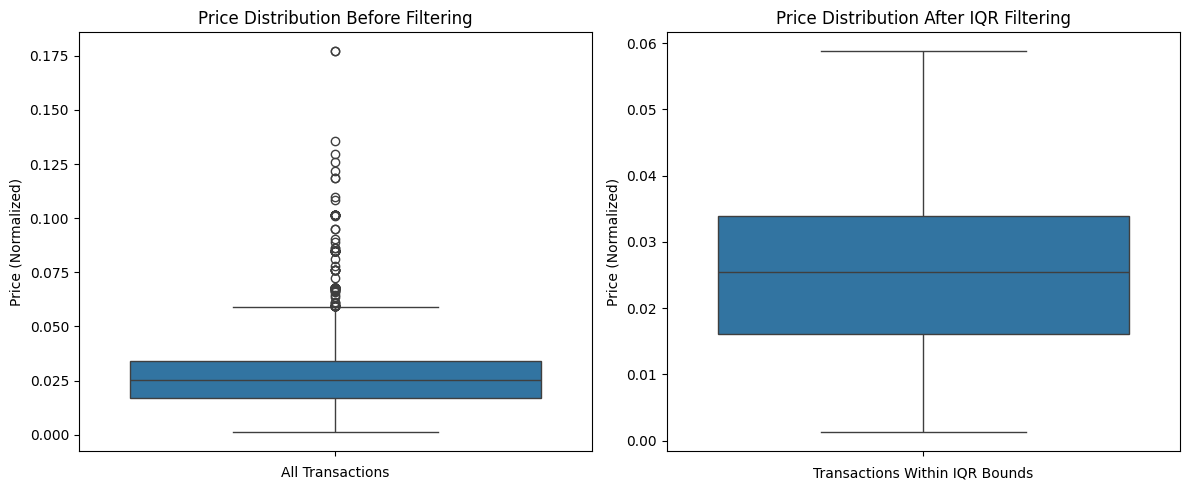

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["price"], ax=axes[0])
axes[0].set_title("Price Distribution Before Filtering")
axes[0].set_xlabel("All Transactions")
axes[0].set_ylabel("Price (Normalized)")

sns.boxplot(
    y=df.loc[~df["price_outlier"], "price"],
    ax=axes[1],
)
axes[1].set_title("Price Distribution After IQR Filtering")
axes[1].set_xlabel("Transactions Within IQR Bounds")
axes[1].set_ylabel("Price (Normalized)")

plt.tight_layout()
plt.show()

## 5. 이미지 피처 생성

상품 이미지를 NumPy 배열로 읽고 전체 픽셀 값의 평균과 표준편차를 계산한다.

- image_mean: 픽셀 값의 평균
- image_std: 픽셀 값의 표준편차

RGB 채널을 포함한 전체 값으로 계산하며, 픽셀 값은 0~1로 정규화한다.
이미지가 없는 상품은 결측치로 유지한다.

파일은 상품별로 하나씩 읽고, 각 이미지 안의 픽셀 통계는 NumPy 배열 연산으로 계산한다. 같은 상품이 여러 거래에 등장하면 계산한 피처를 재사용한다.

In [82]:
articles = analyzer.add_image_features(articles)

print("이미지 처리 완료")
print("이미지가 없는 상품 수:", articles["image_mean"].isna().sum())
display(articles[["article_id", "image_mean", "image_std"]].head())

이미지 처리 완료
이미지가 없는 상품 수: 4


In [ ]:
image_features = articles.set_index("article_id")
df["image_mean"] = df["article_id"].map(image_features["image_mean"])
df["image_std"] = df["article_id"].map(image_features["image_std"])

display(df[["article_id", "image_mean", "image_std"]].head())

In [ ]:
images_with_features = articles.dropna(subset=["image_mean", "image_std"])
image_examples = images_with_features.sample(
    n=min(3, len(images_with_features)), random_state=RANDOM_SEED
).sort_values("image_mean")

if image_examples.empty:
    print("표시할 상품 이미지가 없습니다.")
else:
    fig, axes = plt.subplots(1, len(image_examples), figsize=(9, 3.6), squeeze=False)

    for ax, article in zip(axes[0], image_examples.itertuples()):
        ax.imshow(mpimg.imread(analyzer.image_path(article.article_id)), cmap="gray")
        ax.set_title(
            f"{article.article_id}\nMean {article.image_mean:.3f} | Std {article.image_std:.3f}",
            fontsize=10,
        )
        ax.axis("off")

    fig.suptitle("Product Image Examples")
    fig.tight_layout()
    plt.show()

## 6. 통계 분석

가격, 상품명 길이, 이미지 평균·표준편차의 분포를 확인하고,
변수 간 피어슨 상관계수를 계산한다.

거래 데이터를 기준으로 계산하므로 여러 번 구매된 상품은 반복 반영된다.
상관관계는 인과관계를 의미하지 않는다.

정규화 가격의 평균은 0.0286, 중앙값은 0.0254, 표준편차는 0.0181이다. 가운데 절반은 약 0.0169에서 0.0339 사이에 있고 최대값은 0.1771이다. 가격의 상단에 긴 꼬리가 있으므로 대표 가격대를 설명할 때 중앙값과 사분위수를 함께 본다. 가격과 이미지 평균의 상관계수는 −0.1277, 가격과 이미지 표준편차의 상관계수는 0.1204다. 두 값 모두 0에 가까워 이미지 통계만으로 거래 가격 차이를 설명하기 어렵다.

In [85]:
display(
    analyzer.summarize(
        df, ["price", "product_name_length", "image_mean", "image_std"]
    ).round(4)
)

,price,product_name_length,image_mean,image_std
count,2606.0000,2606.0000,2602.0000,2602.0000
mean,0.0286,15.5668,0.7407,0.2458
std,0.0181,6.1790,0.1184,0.1162
min,0.0013,3.0000,0.0951,0.0112
25%,0.0169,11.0000,0.6600,0.1503
50%,0.0254,15.0000,0.7524,0.2722
75%,0.0339,20.0000,0.8352,0.3474
max,0.1771,30.0000,0.9848,0.4610


In [86]:
print(
    "가격과 이미지 평균의 상관계수:",
    round(df["price"].corr(df["image_mean"]), 4),
)

print(
    "가격과 이미지 표준편차의 상관계수:",
    round(df["price"].corr(df["image_std"]), 4),
)

가격과 이미지 평균의 상관계수: -0.1277
가격과 이미지 표준편차의 상관계수: 0.1204


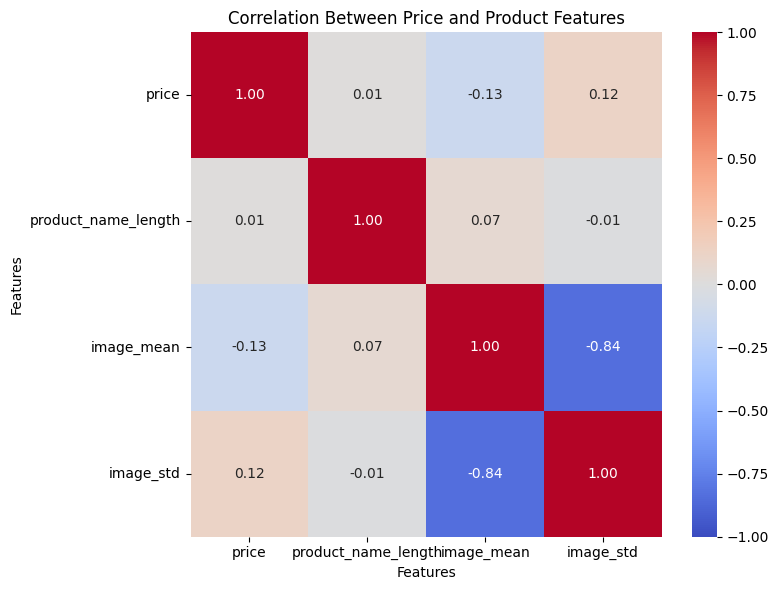

In [87]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[
        ["price", "product_name_length", "image_mean", "image_std"]
    ].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Correlation Between Price and Product Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

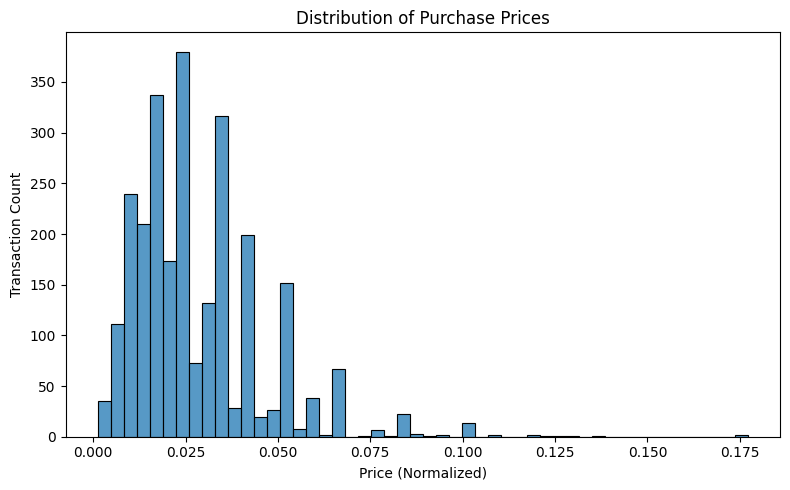

In [108]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="price", bins=50)

plt.title("Distribution of Purchase Prices")
plt.xlabel("Price (Normalized)")
plt.ylabel("Transaction Count")
plt.tight_layout()
plt.show()

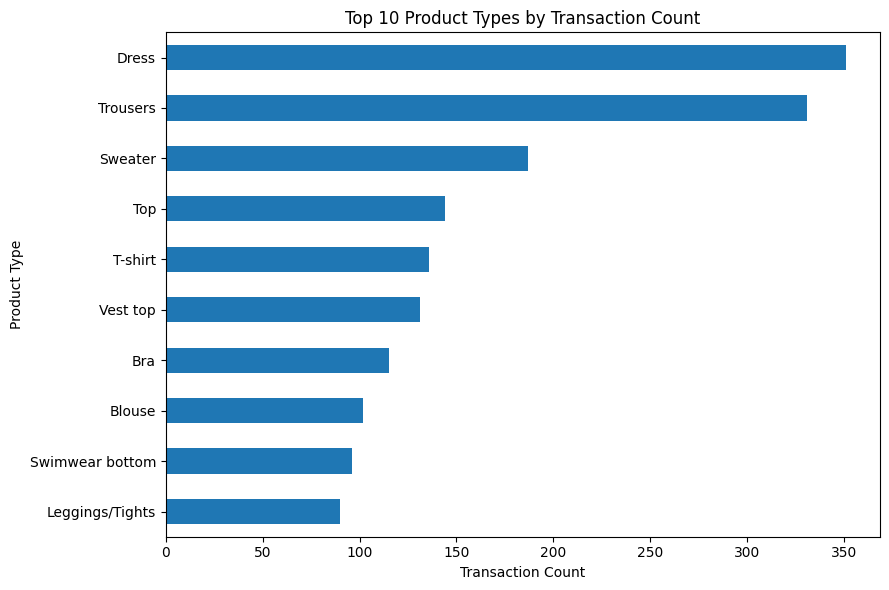

In [89]:
df["product_type_name"].value_counts().head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
)

plt.title("Top 10 Product Types by Transaction Count")
plt.xlabel("Transaction Count")
plt.ylabel("Product Type")
plt.tight_layout()
plt.show()

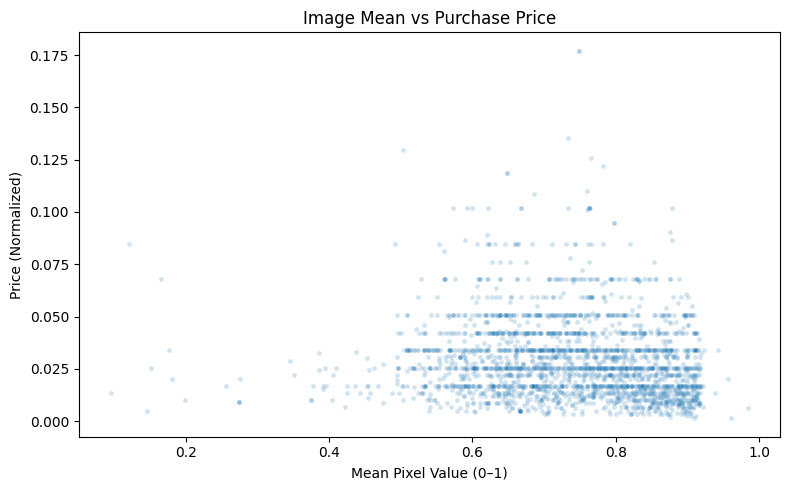

In [90]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="image_mean",
    y="price",
    alpha=0.2,
    s=12,
)

plt.title("Image Mean vs Purchase Price")
plt.xlabel("Mean Pixel Value (0–1)")
plt.ylabel("Price (Normalized)")
plt.tight_layout()
plt.show()

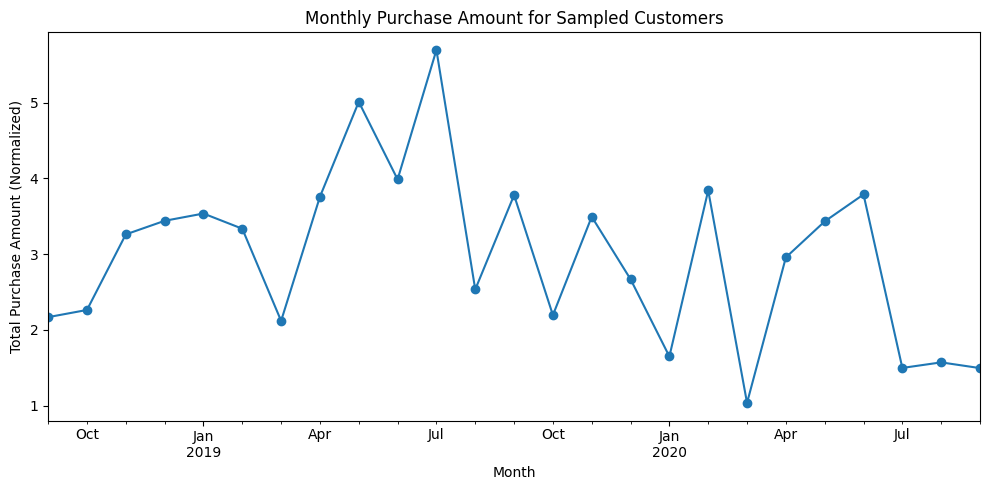

In [91]:
df.resample(
    "MS",
    on="t_dat",
)["price"].sum().plot(
    figsize=(10, 5),
    marker="o",
)

plt.title("Monthly Purchase Amount for Sampled Customers")
plt.xlabel("Month")
plt.ylabel("Total Purchase Amount (Normalized)")
plt.tight_layout()
plt.show()

## 7. RFM 고객 분석

분석 기준일은 표본 거래 데이터의 최종 거래일로 설정한다.

- Recency: 분석 기준일부터 마지막 구매일까지의 경과 일수
- Frequency: 고객별 서로 다른 구매 날짜 수
- Monetary: 고객별 정규화된 구매 가격의 합계

가격 이상치 후보와 동일한 거래 행도 유지한다.
고가 상품 및 동일 상품의 반복 구매가 고객 구매금액에 반영되도록 한다.

In [92]:
reference_date = df["t_dat"].max()

print("분석 기준일:", reference_date)

분석 기준일: 2020-09-21 00:00:00


In [93]:
rfm = analyzer.calculate_rfm(df, reference_date=reference_date)

print("RFM 고객 수:", len(rfm))
display(rfm.head())

RFM 고객 수: 100


In [94]:
display(rfm.describe().round(2))

,recency,frequency,monetary
count,100.00,100.00,100.00
mean,250.97,6.73,0.75
std,231.58,9.58,1.95
min,0.00,1.00,0.02
25%,56.50,1.00,0.11
50%,131.50,3.00,0.20
75%,456.50,7.00,0.53
max,729.00,46.00,17.58


## 8. RFM 점수와 고객 세분화

각 지표의 상대적 순위를 기준으로 1~5점을 부여한다.

- Recency: 경과 일수가 짧을수록 높은 점수
- Frequency: 구매 날짜 수가 많을수록 높은 점수
- Monetary: 구매금액 합계가 클수록 높은 점수

동일한 값에는 동일한 점수를 부여한다.
따라서 점수별 고객 수가 정확히 같지는 않을 수 있다.

In [ ]:
rfm["r_score"] = np.ceil(
    rfm["recency"].rank(ascending=False, pct=True) * 5
).astype(int)

rfm["f_score"] = np.ceil(
    rfm["frequency"].rank(pct=True) * 5
).astype(int)

rfm["m_score"] = np.ceil(
    rfm["monetary"].rank(pct=True) * 5
).astype(int)

display(rfm.head())

### RFM 세그먼트 분류 기준

고객별 최근성(R), 구매 빈도(F), 구매 금액(M)의 상대 순위를 1점부터 5점으로 환산한다. 마지막 구매가 최근일수록 R, 구매일 수가 많을수록 F, 정규화 가격 합계가 클수록 M 점수가 높다. 순위 비율에 5를 곱해 올림하므로 4점과 5점은 상위 약 40%에 해당한다. 동점에는 평균 순위를 적용하므로 실제 비율은 달라질 수 있다.

| 우선순위 | 세그먼트 | 분류 조건 | 기준을 둔 이유 |
| --- | --- | --- | --- |
| 1 | VIP | `R ≥ 4`, `F ≥ 4`, `M ≥ 4` | 최근에 구매했고, 자주 구매하고, 구매 금액도 높은 고객 |
| 2 | Loyal | `R ≥ 3`, `F ≥ 4` | 최근성 기준을 완화하고 반복 구매를 중심으로 분류 |
| 3 | New | `R ≥ 4`, `frequency == 1` | 최근에 구매했고 관측 기간에 구매한 날짜가 하루인 고객 |
| 4 | At Risk | `R ≤ 2` | 마지막 구매가 표본 내에서 상대적으로 오래된 고객 |
| 5 | Regular | 앞선 조건 중 충족한 조건이 없음 | 기본 분류 |

`np.select`는 위에서부터 처음 충족한 조건을 적용한다. 예를 들어 VIP와 Loyal 조건을 모두 충족하면 VIP로 분류한다.

In [96]:
rfm["segment"] = np.select(
    [
        (rfm["r_score"] >= 4)
        & (rfm["f_score"] >= 4)
        & (rfm["m_score"] >= 4),

        (rfm["r_score"] >= 3)
        & (rfm["f_score"] >= 4),

        (rfm["r_score"] >= 4)
        & (rfm["frequency"] == 1),

        rfm["r_score"] <= 2,
    ],
    [
        "VIP",
        "Loyal",
        "New",
        "At Risk",
    ],
    default="Regular",
)

display(rfm["segment"].value_counts())
print("세그먼트 수:", rfm["segment"].nunique())

segment
At Risk    40
Regular    25
VIP        24
Loyal       8
New         3
Name: count, dtype: int64

세그먼트 수: 5


In [97]:
display(
    rfm.groupby("segment").agg(
        customer_count=("monetary", "size"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    ).round(4)
)

,customer_count,avg_recency,avg_frequency,avg_monetary,total_monetary
segment,,,,,
At Risk,40,505.4500,2.125,0.2250,8.9990
Loyal,8,127.8750,11.250,0.9212,7.3692
New,3,56.3333,1.000,0.1032,0.3095
Regular,25,108.4800,2.160,0.1637,4.0931
VIP,24,40.6250,18.375,2.2389,53.7334


## 9. 비즈니스 인사이트

### 분석 범위

고정 시드(42)로 뽑은 고객 100명의 거래 2,606행과 상품 2,152개를 분석했다. RFM 기준일은 표본의 마지막 거래일인 2020-09-21이다. Frequency는 서로 다른 구매 날짜 수이고, Monetary는 정규화 가격의 합계다. 금액 비중은 표에 표시된 세그먼트별 합계를 기준으로 계산했다. 아래 캠페인은 이 표본의 관측 결과를 바탕으로 제안하는 검증 가설이다.

| 세그먼트 | 고객 수 (비중) | 마지막 구매 후 평균 일수 | 평균 구매일 수 | 정규화 구매금액 합계 | 금액 비중 |
| --- | ---: | ---: | ---: | ---: | ---: |
| VIP | 24명 (24%) | 40.63 | 18.38 | 53.7334 | 72.12% |
| Loyal | 8명 (8%) | 127.88 | 11.25 | 7.3692 | 9.89% |
| Regular | 25명 (25%) | 108.48 | 2.16 | 4.0931 | 5.49% |
| At Risk | 40명 (40%) | 505.45 | 2.13 | 8.9990 | 12.08% |
| New | 3명 (3%) | 56.33 | 1.00 | 0.3095 | 0.42% |

### 1. VIP 고객 유지

VIP 24명이 관측 기간 구매금액의 약 72.12%를 차지했다. 평균 구매일 수는 18.38일이었고, 마지막 구매는 기준일로부터 평균 40.63일 전이었다. VIP는 구매금액 점수를 포함해 정의했으므로, 이 비중은 표본 내 구매금액 집중을 보여준다. 선호 상품군의 신상품이나 재입고를 안내하는 실험을 하고, VIP 내 대조군과 이후 동일 기간의 재구매율과 고객당 구매금액을 비교한다.

### 2. At Risk 고객 중 재활성화 대상 선별

At Risk는 40명이며 마지막 구매 후 평균 505.45일이 지났다. 관측 기간 구매금액 비중은 약 12.08%였다. 표본에서 At Risk가 차지한 40%는 상대 순위 기준으로 분류한 결과다. 과거 구매금액과 평소 구매 간격을 함께 보고 연락 대상을 좁힌 뒤, 대조군과 후속 구매율을 비교한다.

### 3. Loyal과 Regular의 다음 구매 유도

Loyal은 평균 구매일 수가 11.25일로 Regular의 2.16일보다 많았다. 마지막 구매 후 평균 경과 일수는 Loyal 127.88일, Regular 108.48일이었다. Loyal에는 반복 구매한 상품군의 후속 상품 안내를, Regular에는 관심 상품과 함께 구매할 만한 상품 추천을 시험할 수 있다. 각 세그먼트 안에서 대조군을 두고 후속 구매일 수를 비교한다.

### 4. New 고객의 두 번째 구매일 관찰

New는 3명이며 모두 관측 기간에 구매한 날짜가 하루였다. 마지막 구매 후 평균 56.33일이 지났다. 가입일이나 관측 기간 이전의 구매 이력이 필요하므로, 여기서는 첫 관측 구매일 이후 다음 구매일이 생기는지를 볼 수 있는 소규모 그룹으로 해석한다. 더 큰 표본에서 후속 기간에 두 번째 구매일이 생긴 고객 비율을 비교한다.

### 보조 분석. 가격 분포와 이미지 통계

가격의 IQR 기준을 벗어난 거래는 167행(6.41%)이었다. 해당 행을 표시해 가격 분포를 비교했고, RFM에는 전체 거래를 사용했다. 가격과 이미지 평균의 피어슨 상관계수는 -0.1277, 가격과 이미지 표준편차는 0.1204로, 두 관계 모두 선형 상관이 약했다. 이미지가 없는 상품 4개에 해당하는 거래 4행을 제외한 2,602행으로 상관계수를 계산했다. 같은 상품이 여러 번 팔리면 이미지 값이 거래마다 반복되므로, 상품 수준의 관계는 상품별로 집계한 뒤 상품군 안에서 따로 확인할 수 있다.